# 08 — Decision Trees, Random Forests, and Feature Importance

## Notebook description

Notebook 07 compares model families and selects configurations. **This notebook asks a different question: which historical and product signals do tree models actually use?** It fits small readable trees and fixed Random Forests on the same chronological development windows, then checks feature importance. It does not repeat the full model search or use the reserved test set.

## Objectives

- Show readable regression and classification tree rules.
- Give a brief tree-versus-forest performance context, including simple baselines.
- Compare impurity-based and chronological permutation importance.
- Check whether important features remain important across later windows and both tasks.
- Interpret predictive associations without claiming causality.

## Planned sections

1. Data, metrics, and comparison policy
2. Interpretable regression tree
3. Regression Random Forest and importance
4. Interpretable classification tree
5. Classification Random Forest and importance
6. Impurity versus permutation importance
7. Stability across tasks and periods
8. Interpretation, caveats, and conclusions

## 1. Data, metrics, and comparison policy

The 02 publication supplies article-week rows, historical predictors, and the fixed high-demand label. We reuse notebook 07's deterministic limit of 2,000 rows per target week and its final three chronological development windows. **Only train and validation rows enter this notebook.** Test rows are not loaded into the working sample.

Each outer window fits on all earlier sampled weeks and evaluates on the following four weeks. A shallow depth-3 tree is chosen for readable rules; the Random Forest uses the fixed settings from notebook 07. These are explanatory comparisons, not a new hyperparameter search. Numeric inputs are not scaled here, so tree split thresholds remain in original units such as sales counts; scaling is unnecessary for trees. Regression uses MAE (units; lower is better), classification uses PR-AUC (higher is better). The corresponding simple rules are current-week sales and current-week sales crossing the fixed high-demand threshold.

**Code walkthrough.** The next cell checks the publication, takes the same reproducible weekly sample, builds later windows, and defines preprocessing and score helpers. Missing values and category codes are learned inside each training window.

In [1]:
from hashlib import sha256
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import RandomForestClassifier, RandomForestRegressor
from sklearn.impute import SimpleImputer
from sklearn.inspection import permutation_importance
from sklearn.metrics import average_precision_score, mean_absolute_error
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder
from sklearn.tree import DecisionTreeClassifier, DecisionTreeRegressor, plot_tree

SEED = 42
MAX_ROWS_PER_WEEK = 2_000
PERMUTATION_ROWS_PER_FOLD = 1_000
PERMUTATION_REPEATS = 3
OUTER_FOLDS = 3
OUTER_WEEKS = 4
PAPER, INK, MUTED, GRID = "#FAFBFC", "#17212B", "#667085", "#DDE3EA"
BLUE, TEAL = "#2F6BFF", "#16A085"

ROOT = next((path for path in [Path.cwd(), *Path.cwd().parents]
             if (path / "src/data/process_data.py").is_file()
             and (path / "data/processed/CURRENT.json").is_file()), None)
if ROOT is None:
    raise FileNotFoundError("Open this notebook from the fashion-demand-ml project.")
processed_dir = ROOT / "data/processed"
pointer = json.loads((processed_dir / "CURRENT.json").read_text(encoding="utf-8"))
run_dir = (processed_dir / pointer["run_dir"]).resolve()
if not run_dir.is_relative_to(processed_dir.resolve()) or pointer.get("preview"):
    raise ValueError("The selected publication is not a complete processed run.")
summary = json.loads((run_dir / "summary.json").read_text(encoding="utf-8"))
HIGH_DEMAND_THRESHOLD = int(summary["classification_target"]["threshold_units"])
checksums = json.loads((run_dir / "checksums.json").read_text(encoding="utf-8"))
data_path = run_dir / "article_week.csv.gz"
digest = sha256()
with data_path.open("rb") as stream:
    for block in iter(lambda: stream.read(4 * 1024 * 1024), b""):
        digest.update(block)
if digest.hexdigest() != checksums[data_path.name]:
    raise ValueError("The processed article-week file fails its checksum check.")

NUMERIC_FEATURES = [
    "sales", "lag_1_sales", "lag_2_sales", "lag_4_sales", "lag_12_sales",
    "rolling_4w_sales_mean", "rolling_4w_sales_std", "rolling_4w_active_weeks",
    "rolling_12w_sales_mean", "rolling_12w_sales_std", "rolling_12w_active_weeks",
    "sales_trend_4w", "mean_price", "rolling_4w_mean_price",
    "price_change_from_4w_mean", "rolling_4w_online_share", "week_sin", "week_cos",
]
CATEGORICAL_FEATURES = [
    "product_type_name", "product_group_name", "index_group_name",
    "section_name", "garment_group_name", "colour_group_name",
]
FEATURES = NUMERIC_FEATURES + CATEGORICAL_FEATURES
SOURCE_COLUMNS = list(dict.fromkeys([
    "article_id", "split", "target_week", "iso_week",
    "target_next_week_sales", "target_high_demand",
    *[name for name in NUMERIC_FEATURES if name not in ("week_sin", "week_cos")],
    *CATEGORICAL_FEATURES,
]))
FORBIDDEN = {"article_id", "split", "target_week", "target_next_week_sales", "target_high_demand"}
if FORBIDDEN.intersection(FEATURES):
    raise ValueError("A target, date, split, or ID was included among predictors.")

# Keep the smallest hash keys within each target week, exactly as in notebook 07.
weekly_sample = {}
for chunk in pd.read_csv(data_path, usecols=SOURCE_COLUMNS,
                         dtype={"article_id": "string"}, parse_dates=["target_week"],
                         chunksize=250_000):
    chunk = chunk.loc[chunk["split"].isin(["train", "validation"])].copy()
    if chunk.empty:
        continue
    key = chunk["article_id"].astype("string") + "|" + chunk["target_week"].dt.strftime("%Y-%m-%d")
    chunk["_sample_hash"] = pd.util.hash_pandas_object(
        key, index=False, hash_key="fashion-demand07").to_numpy(dtype="uint64")
    for week, group in chunk.groupby("target_week", sort=False):
        kept = group.nsmallest(MAX_ROWS_PER_WEEK, "_sample_hash")
        weekly_sample[week] = pd.concat(
            [weekly_sample[week], kept], ignore_index=True
        ).nsmallest(MAX_ROWS_PER_WEEK, "_sample_hash") if week in weekly_sample else kept
if not weekly_sample:
    raise ValueError("No development rows were found.")
development = pd.concat(
    [weekly_sample[week] for week in sorted(weekly_sample)], ignore_index=True
).drop(columns=["article_id", "_sample_hash"])
assert not development["split"].eq("test").any()
assert development["target_next_week_sales"].ge(0).all()
expected_class = development["target_next_week_sales"].ge(HIGH_DEMAND_THRESHOLD).astype("int8")
assert development["target_high_demand"].eq(expected_class).all()
development["week_sin"] = np.sin(2 * np.pi * (development["iso_week"] - 1) / 52.1775)
development["week_cos"] = np.cos(2 * np.pi * (development["iso_week"] - 1) / 52.1775)
for name in CATEGORICAL_FEATURES:
    development[name] = development[name].fillna("Unknown").astype(str)

weeks = pd.DatetimeIndex(sorted(development["target_week"].unique()))
if len(weeks) < 20 + OUTER_FOLDS * OUTER_WEEKS:
    raise ValueError("Too few development weeks for the planned outer windows.")
outer_folds = []
first_start = len(weeks) - OUTER_FOLDS * OUTER_WEEKS
for number in range(OUTER_FOLDS):
    start = first_start + number * OUTER_WEEKS
    outer_folds.append({"fold": number + 1, "train_weeks": weeks[:start],
                        "validation_weeks": weeks[start:start + OUTER_WEEKS]})

def rows_for_weeks(frame, selected_weeks):
    return frame.loc[frame["target_week"].isin(selected_weeks)]

def feature_frame(frame):
    return frame.loc[:, FEATURES]

preprocessor = ColumnTransformer([
    ("numeric", Pipeline([
        ("imputer", SimpleImputer(strategy="median", add_indicator=True)),
    ]), NUMERIC_FEATURES),
    ("categorical", Pipeline([
        ("imputer", SimpleImputer(strategy="constant", fill_value="Unknown")),
        ("onehot", OneHotEncoder(handle_unknown="ignore", min_frequency=25,
                                  max_categories=80, sparse_output=True)),
    ]), CATEGORICAL_FEATURES),
], remainder="drop", sparse_threshold=0.3)

def model_pipeline(estimator):
    return Pipeline([("preprocessor", clone(preprocessor)), ("model", clone(estimator))])

def regression_mae(actual, raw_prediction):
    return mean_absolute_error(actual, np.maximum(raw_prediction, 0))

def classification_pr_auc(actual, probability):
    return average_precision_score(actual, probability)

def short_feature_names(pipeline):
    return [name.split("__", 1)[-1].replace("missingindicator_", "missing: ")
            for name in pipeline.named_steps["preprocessor"].get_feature_names_out()]

def raw_feature_name(transformed_name):
    name = transformed_name.split("__", 1)[-1]
    if name.startswith("missingindicator_"):
        name = name[len("missingindicator_"):]
    if name in NUMERIC_FEATURES:
        return name
    for feature in CATEGORICAL_FEATURES:
        if name.startswith(feature + "_"):
            return feature
    raise ValueError(f"Cannot map transformed feature: {transformed_name}")

def feature_importance_rows(model, task, fold_number, evaluation, target, scoring):
    names = model.named_steps["preprocessor"].get_feature_names_out()
    raw_names = [raw_feature_name(name) for name in names]
    impurity = pd.Series(model.named_steps["model"].feature_importances_).groupby(raw_names).sum()
    if not np.isclose(impurity.sum(), 1.0):
        raise ValueError("Grouped impurity importance does not sum to one.")
    impurity_rows = pd.DataFrame({"task": task, "fold": fold_number,
                                 "feature": FEATURES, "impurity_share": impurity.reindex(FEATURES, fill_value=0).to_numpy()})
    permutation = permutation_importance(
        model, feature_frame(evaluation), target, scoring=scoring,
        n_repeats=PERMUTATION_REPEATS, random_state=SEED + fold_number, n_jobs=1,
    )
    permutation_rows = pd.DataFrame({
        "task": task, "fold": fold_number, "feature": FEATURES,
        "permutation_effect": permutation.importances_mean,
        "repeat_sd": permutation.importances_std,
    })
    return impurity_rows, permutation_rows

plt.rcParams.update({"font.family": ["Arial", "DejaVu Sans"],
                     "font.size": 9, "text.color": INK, "axes.labelcolor": INK,
                     "xtick.color": MUTED, "ytick.color": MUTED,
                     "figure.facecolor": PAPER, "axes.facecolor": PAPER})

def add_source(fig, note):
    fig.text(0.01, 0.012, note, ha="left", va="bottom", fontsize=8, color=MUTED)

def save_figure(fig, suffix):
    folder = ROOT / "results" / "figures"
    folder.mkdir(parents=True, exist_ok=True)
    stem = f"08_tree_rf_feature_importance_{run_dir.name}_{suffix}"
    fig.savefig(folder / f"{stem}.svg", bbox_inches="tight", facecolor=PAPER)
    fig.savefig(folder / f"{stem}.png", dpi=300, bbox_inches="tight", facecolor=PAPER)

print("Selected run:", run_dir.name)
print("Development sample:", f"{len(development):,}", "article-weeks over", len(weeks), "weeks")
print("High-demand label: next-week sales >=", HIGH_DEMAND_THRESHOLD)
print("Permutation budget:", PERMUTATION_ROWS_PER_FOLD, "rows per fold x", PERMUTATION_REPEATS, "repeats")
display(pd.DataFrame([{"fold": fold["fold"],
                       "train_end": fold["train_weeks"].max(),
                       "validation_start": fold["validation_weeks"].min(),
                       "validation_end": fold["validation_weeks"].max(),
                       "validation_rows": int(development["target_week"].isin(fold["validation_weeks"]).sum())}
                      for fold in outer_folds]))


Selected run: 20261027T145552-5a1ac59a
Development sample: 154,000 article-weeks over 77 weeks
High-demand label: next-week sales >= 16
Permutation budget: 1000 rows per fold x 3 repeats


,fold,train_end,validation_start,validation_end,validation_rows
0,1,2020-03-16,2020-03-23,2020-04-13,8000
1,2,2020-04-13,2020-04-20,2020-05-11,8000
2,3,2020-05-11,2020-05-18,2020-06-08,8000


## 2. Interpretable regression tree

A depth-3 tree is deliberately small: each split asks one yes/no question about a known predictor. We fit the representative tree on the first outer training window, then evaluate it on that window's later weeks. The drawing shows this **one fitted tree**, not a universal rule or the best model from notebook 07.

**Code walkthrough.** The next cell fits the shallow tree, measures its validation MAE, and draws every split. The preprocessing and tree learn only from earlier weeks.

Representative regression tree: fold 1 MAE=11.152; depth=3; validation n=8,000.


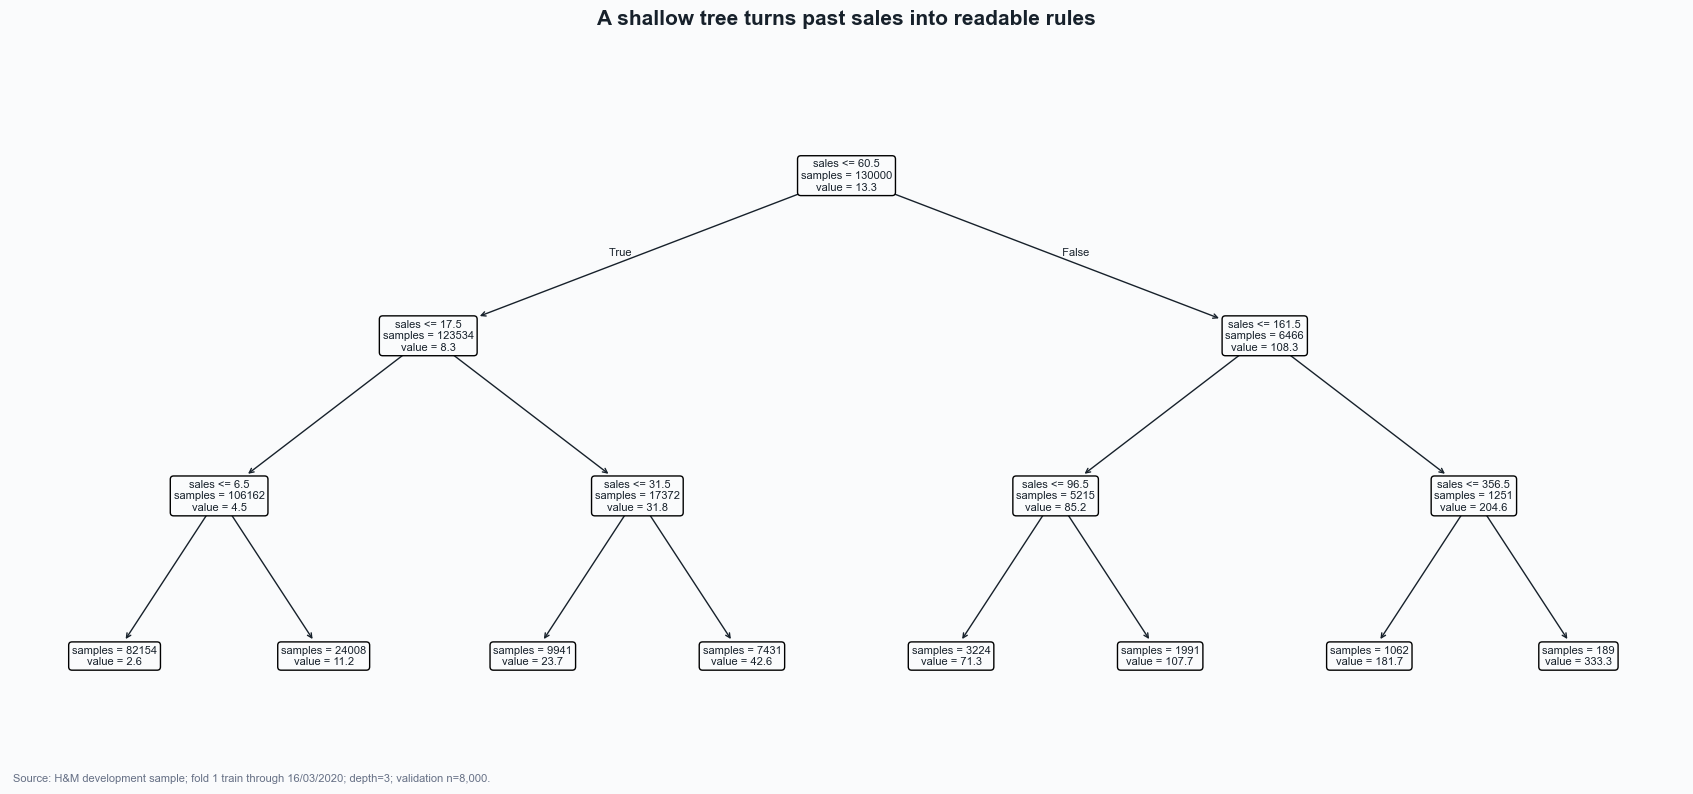

In [2]:
REGRESSION_TREE = DecisionTreeRegressor(
    max_depth=3, min_samples_leaf=100, random_state=SEED)
representative_fold = outer_folds[0]
representative_train = rows_for_weeks(development, representative_fold["train_weeks"])
representative_validation = rows_for_weeks(development, representative_fold["validation_weeks"])
regression_tree_model = model_pipeline(REGRESSION_TREE)
regression_tree_model.fit(feature_frame(representative_train),
                          representative_train["target_next_week_sales"])
regression_tree_mae = regression_mae(
    representative_validation["target_next_week_sales"],
    regression_tree_model.predict(feature_frame(representative_validation)),
)
print(f"Representative regression tree: fold 1 MAE={regression_tree_mae:.3f}; depth=3; "
      f"validation n={len(representative_validation):,}.")
fig, ax = plt.subplots(figsize=(17, 8))
plot_tree(regression_tree_model.named_steps["model"],
          feature_names=short_feature_names(regression_tree_model),
          filled=False, rounded=True, impurity=False, precision=1, fontsize=8, ax=ax)
ax.axis("off")
fig.suptitle("A shallow tree turns past sales into readable rules", fontsize=15,
             fontweight="bold", y=0.98)
fig.tight_layout(rect=(0, 0.055, 1, 0.93))
add_source(fig, f"Source: H&M development sample; fold 1 train through {representative_fold['train_weeks'].max():%d/%m/%Y}; depth=3; validation n={len(representative_validation):,}.")
save_figure(fig, "regression_tree")
plt.show()


## 3. Regression Random Forest and importance

A Random Forest averages many trees, so it can capture more patterns but cannot be read as a single short rule. Its fixed settings match the Random Forest candidate in notebook 07. We show only tree, forest, and current-sales baseline here: the full model competition belongs to 07.

The forest's built-in impurity importance measures how often a variable improves training splits. Permutation importance asks a different question on **later validation rows**: how much does MAE worsen when one original input column is shuffled? We use the same 1,000 randomly selected validation rows and three shuffles in each fold for a manageable, reproducible check. Positive permutation effect means the feature helped this model on that sample.

**Code walkthrough.** The next cell fits a tree and forest in each of the three temporal windows, records their MAE, and computes both importance measures for the forest. The first fold reuses the already fitted readable tree.

In [3]:
REGRESSION_FOREST = RandomForestRegressor(
    n_estimators=30, max_depth=12, min_samples_leaf=100, max_features=0.7,
    n_jobs=-1, random_state=SEED)
regression_performance = []
regression_impurity_parts = []
regression_permutation_parts = []
for fold in outer_folds:
    training = rows_for_weeks(development, fold["train_weeks"])
    validation = rows_for_weeks(development, fold["validation_weeks"])
    truth = validation["target_next_week_sales"]
    tree_model = regression_tree_model if fold["fold"] == 1 else model_pipeline(REGRESSION_TREE)
    if fold["fold"] != 1:
        tree_model.fit(feature_frame(training), training["target_next_week_sales"])
    forest_model = model_pipeline(REGRESSION_FOREST)
    forest_model.fit(feature_frame(training), training["target_next_week_sales"])
    for method, prediction in [
        ("Current-sales rule", validation["sales"].to_numpy()),
        ("Shallow tree", tree_model.predict(feature_frame(validation))),
        ("Random Forest", forest_model.predict(feature_frame(validation))),
    ]:
        regression_performance.append({"fold": fold["fold"], "method": method,
                                       "n": len(validation),
                                       "MAE": regression_mae(truth, prediction)})
    importance_sample = validation.sample(
        n=min(PERMUTATION_ROWS_PER_FOLD, len(validation)),
        random_state=SEED + fold["fold"])
    impurity, permutation = feature_importance_rows(
        forest_model, "Regression", fold["fold"], importance_sample,
        importance_sample["target_next_week_sales"], "neg_mean_absolute_error")
    regression_impurity_parts.append(impurity)
    regression_permutation_parts.append(permutation)
    print(f"Regression fold {fold['fold']}: tree MAE="
          f"{regression_performance[-2]['MAE']:.3f}; forest MAE="
          f"{regression_performance[-1]['MAE']:.3f}; permutation n={len(importance_sample):,}")
regression_performance = pd.DataFrame(regression_performance)
regression_impurity = pd.concat(regression_impurity_parts, ignore_index=True)
regression_permutation = pd.concat(regression_permutation_parts, ignore_index=True)
display(regression_performance.pivot(index="fold", columns="method", values="MAE").round(3))


Regression fold 1: tree MAE=11.152; forest MAE=10.660; permutation n=1,000


Regression fold 2: tree MAE=8.949; forest MAE=8.292; permutation n=1,000


Regression fold 3: tree MAE=7.571; forest MAE=6.772; permutation n=1,000


method,Current-sales rule,Random Forest,Shallow tree
fold,,,
1,11.557,10.660,11.152
2,8.543,8.292,8.949
3,7.202,6.772,7.571


## 4. Interpretable classification tree

The classification tree uses the same historical predictors but predicts whether next-week recorded sales reach the **fixed 16-unit high-demand threshold** from notebook 02. The threshold is the label definition, not a predictor. Class weighting helps the small tree attend to the less common high-demand class. For this reason, `value` proportions inside the drawing are **class-weighted**, not the observed high-demand prevalence.

**Code walkthrough.** The next cell fits a depth-3 classifier on the first outer training window, scores its probabilities on later weeks with PR-AUC, and draws the complete small tree.

Representative classification tree: fold 1 PR-AUC=0.808; depth=3; validation n=8,000.


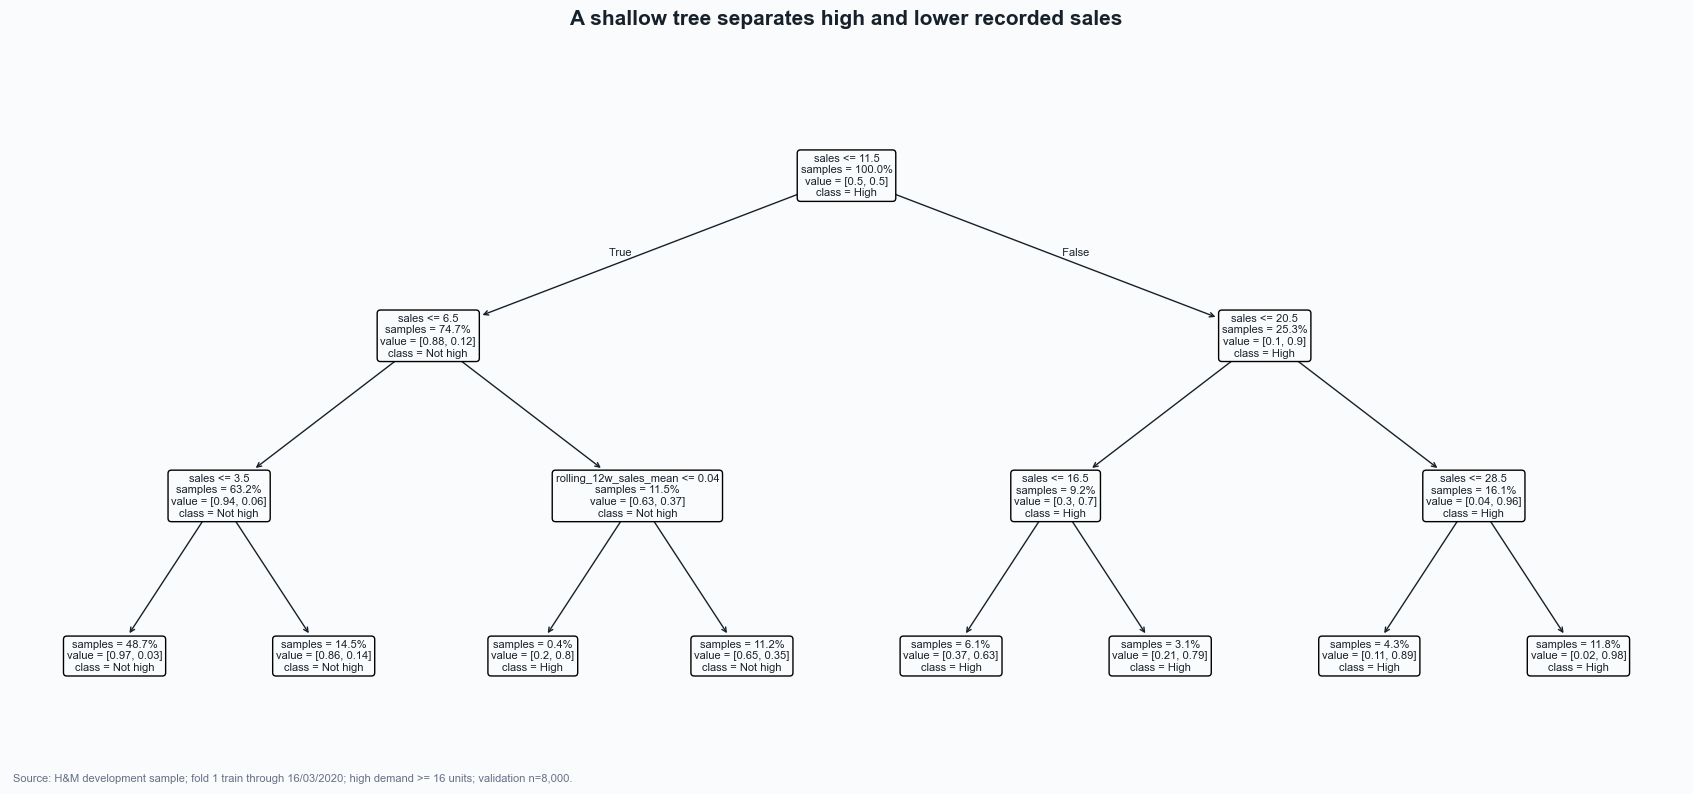

In [4]:
CLASSIFICATION_TREE = DecisionTreeClassifier(
    max_depth=3, min_samples_leaf=100, class_weight="balanced",
    random_state=SEED)
classification_tree_model = model_pipeline(CLASSIFICATION_TREE)
classification_tree_model.fit(feature_frame(representative_train),
                              representative_train["target_high_demand"])
classification_tree_probability = classification_tree_model.predict_proba(
    feature_frame(representative_validation))[:, 1]
classification_tree_pr_auc = classification_pr_auc(
    representative_validation["target_high_demand"], classification_tree_probability)
print(f"Representative classification tree: fold 1 PR-AUC={classification_tree_pr_auc:.3f}; "
      f"depth=3; validation n={len(representative_validation):,}.")
fig, ax = plt.subplots(figsize=(17, 8))
plot_tree(classification_tree_model.named_steps["model"],
          feature_names=short_feature_names(classification_tree_model),
          class_names=["Not high", "High"], filled=False, rounded=True,
          impurity=False, proportion=True, precision=2, fontsize=8, ax=ax)
ax.axis("off")
fig.suptitle("A shallow tree separates high and lower recorded sales", fontsize=15,
             fontweight="bold", y=0.98)
fig.tight_layout(rect=(0, 0.055, 1, 0.93))
add_source(fig, f"Source: H&M development sample; fold 1 train through {representative_fold['train_weeks'].max():%d/%m/%Y}; high demand >= {HIGH_DEMAND_THRESHOLD} units; validation n={len(representative_validation):,}.")
save_figure(fig, "classification_tree")
plt.show()


## 5. Classification Random Forest and importance

The fixed Random Forest uses the same setting as notebook 07's classification candidate. The brief table compares only the tree, forest, and simple current-sales rule; it is context for interpreting feature use, not another model search. PR-AUC is the main score because only about one in five rows has high demand.

For this task, permutation importance is the **drop in PR-AUC** when one input column is shuffled on later validation rows. Its units differ from the regression MAE increase, so compare rankings across tasks rather than raw values.

**Code walkthrough.** The next cell fits the tree and forest across the same three later windows, reports PR-AUC, and collects impurity and permutation importance for classification.

In [5]:
CLASSIFICATION_FOREST = RandomForestClassifier(
    n_estimators=30, max_depth=12, min_samples_leaf=100, max_features="sqrt",
    class_weight="balanced_subsample", n_jobs=-1, random_state=SEED)
classification_performance = []
classification_impurity_parts = []
classification_permutation_parts = []
for fold in outer_folds:
    training = rows_for_weeks(development, fold["train_weeks"])
    validation = rows_for_weeks(development, fold["validation_weeks"])
    truth = validation["target_high_demand"]
    tree_model = classification_tree_model if fold["fold"] == 1 else model_pipeline(CLASSIFICATION_TREE)
    if fold["fold"] != 1:
        tree_model.fit(feature_frame(training), training["target_high_demand"])
    forest_model = model_pipeline(CLASSIFICATION_FOREST)
    forest_model.fit(feature_frame(training), training["target_high_demand"])
    for method, probability in [
        ("Current-sales rule", validation["sales"].ge(HIGH_DEMAND_THRESHOLD).astype(float)),
        ("Shallow tree", tree_model.predict_proba(feature_frame(validation))[:, 1]),
        ("Random Forest", forest_model.predict_proba(feature_frame(validation))[:, 1]),
    ]:
        classification_performance.append({
            "fold": fold["fold"], "method": method, "n": len(validation),
            "PR-AUC": classification_pr_auc(truth, probability)})
    importance_sample = validation.sample(
        n=min(PERMUTATION_ROWS_PER_FOLD, len(validation)),
        random_state=SEED + fold["fold"])
    impurity, permutation = feature_importance_rows(
        forest_model, "Classification", fold["fold"], importance_sample,
        importance_sample["target_high_demand"], "average_precision")
    classification_impurity_parts.append(impurity)
    classification_permutation_parts.append(permutation)
    print(f"Classification fold {fold['fold']}: tree PR-AUC="
          f"{classification_performance[-2]['PR-AUC']:.3f}; forest PR-AUC="
          f"{classification_performance[-1]['PR-AUC']:.3f}; permutation n={len(importance_sample):,}")
classification_performance = pd.DataFrame(classification_performance)
classification_impurity = pd.concat(classification_impurity_parts, ignore_index=True)
classification_permutation = pd.concat(classification_permutation_parts, ignore_index=True)
display(classification_performance.pivot(index="fold", columns="method", values="PR-AUC").round(3))


Classification fold 1: tree PR-AUC=0.808; forest PR-AUC=0.809; permutation n=1,000


Classification fold 2: tree PR-AUC=0.827; forest PR-AUC=0.835; permutation n=1,000


Classification fold 3: tree PR-AUC=0.871; forest PR-AUC=0.883; permutation n=1,000


method,Current-sales rule,Random Forest,Shallow tree
fold,,,
1,0.668,0.809,0.808
2,0.679,0.835,0.827
3,0.719,0.883,0.871


## 6. Impurity versus permutation importance

Impurity importance comes from training splits and can favor variables with many possible split points or categories. We sum one-hot category columns back to their original raw feature so they can be compared with permutation importance, which shuffles one **raw input** at a time. The two measures answer different questions and have different units.

Permutation on later rows is closer to the prediction question, but correlated variables can substitute for one another: shuffling one may have little effect even when the group matters. The regression plot uses two panels with different horizontal scales because shuffling current-week sales has a much larger effect than shuffling any other input; compare numbers within each panel, not bar lengths across panels. Error bars show the **standard deviation across three temporal windows**, not confidence intervals. A small negative permutation effect can arise from sampling noise.

**Code walkthrough.** The next cell summarizes both measures for each task, displays their rankings, and plots the strongest later-window permutation effects with fold-to-fold variation.

Regression: top 10 original features, sorted by later-window permutation effect


,impurity_mean,impurity_fold_sd,permutation_mean,permutation_fold_sd,impurity_rank,permutation_rank
feature,,,,,,
sales,0.7427,0.0359,14.1955,1.2662,1,1
lag_1_sales,0.1444,0.0195,0.3283,0.1065,2,2
rolling_4w_sales_mean,0.0509,0.0119,0.1198,0.0210,3,3
price_change_from_4w_mean,0.0121,0.0027,0.0621,0.0454,5,4
index_group_name,0.0004,0.0000,0.0497,0.0204,18,5
rolling_4w_online_share,0.0026,0.0003,0.0249,0.0216,9,6
rolling_12w_sales_std,0.0035,0.0003,0.0174,0.0279,7,7
rolling_12w_sales_mean,0.0057,0.0011,0.0128,0.0202,6,8
sales_trend_4w,0.0009,0.0006,0.0078,0.0045,13,9


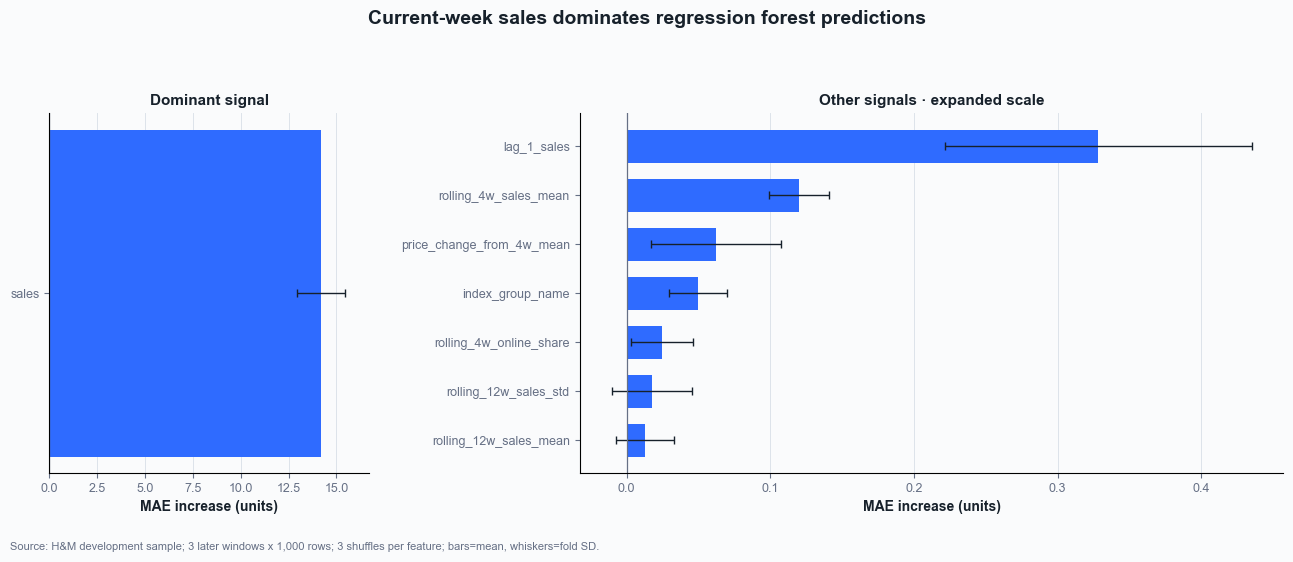

Classification: top 10 original features, sorted by later-window permutation effect


,impurity_mean,impurity_fold_sd,permutation_mean,permutation_fold_sd,impurity_rank,permutation_rank
feature,,,,,,
sales,0.1717,0.0534,0.1297,0.0480,2,1
lag_1_sales,0.1759,0.0414,0.0305,0.0285,1,2
rolling_4w_sales_mean,0.1155,0.0263,0.0098,0.0113,3,3
rolling_12w_sales_mean,0.0621,0.0312,0.0067,0.0030,7,4
lag_2_sales,0.0983,0.0081,0.0063,0.0109,4,5
lag_4_sales,0.0386,0.0070,0.0057,0.0030,8,6
sales_trend_4w,0.0366,0.0136,0.0047,0.0063,9,7
price_change_from_4w_mean,0.0066,0.0002,0.0045,0.0042,17,8
index_group_name,0.0302,0.0019,0.0043,0.0014,10,9


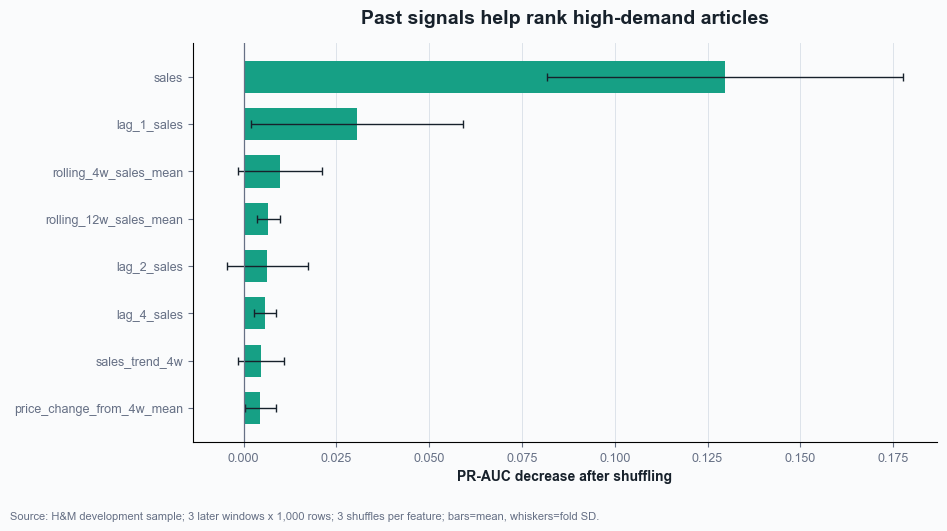

In [6]:
impurity_all = pd.concat([regression_impurity, classification_impurity], ignore_index=True)
permutation_all = pd.concat([regression_permutation, classification_permutation], ignore_index=True)
importance_summaries = {}
for task in ["Regression", "Classification"]:
    impurity = (impurity_all.loc[impurity_all["task"].eq(task)]
                .groupby("feature")["impurity_share"].agg(["mean", "std"]))
    permutation = (permutation_all.loc[permutation_all["task"].eq(task)]
                   .groupby("feature")["permutation_effect"].agg(["mean", "std"]))
    table = impurity.rename(columns={"mean": "impurity_mean", "std": "impurity_fold_sd"}).join(
        permutation.rename(columns={"mean": "permutation_mean", "std": "permutation_fold_sd"}))
    table["impurity_rank"] = table["impurity_mean"].rank(ascending=False, method="min").astype(int)
    table["permutation_rank"] = table["permutation_mean"].rank(ascending=False, method="min").astype(int)
    table = table.sort_values("permutation_mean", ascending=False)
    importance_summaries[task] = table
    print(f"{task}: top 10 original features, sorted by later-window permutation effect")
    display(table.head(10).round(4))
    if task == "Regression":
        # One feature is over 40 times stronger than the next; separate scales
        # show both its dominance and the smaller nonzero effects honestly.
        assert table.index[0] == "sales"
        dominant = table.loc["sales"]
        others = table.drop(index="sales").head(7).sort_values("permutation_mean")
        fig, (ax_sales, ax_others) = plt.subplots(
            1, 2, figsize=(13, 5.6), gridspec_kw={"width_ratios": [1, 2.2]})
        ax_sales.barh(["sales"], [dominant["permutation_mean"]], color=BLUE, height=0.5)
        ax_sales.errorbar([dominant["permutation_mean"]], ["sales"],
                          xerr=[dominant["permutation_fold_sd"]], fmt="none",
                          ecolor=INK, elinewidth=1, capsize=3)
        ax_sales.set_xlim(0, dominant["permutation_mean"] +
                          2 * dominant["permutation_fold_sd"])
        ax_sales.set_title("Dominant signal", fontsize=11, fontweight="bold")
        ax_others.barh(others.index, others["permutation_mean"], color=BLUE, height=0.68)
        ax_others.errorbar(others["permutation_mean"], others.index,
                           xerr=others["permutation_fold_sd"], fmt="none",
                           ecolor=INK, elinewidth=1, capsize=3)
        ax_others.set_title("Other signals · expanded scale", fontsize=11,
                            fontweight="bold")
        for ax in (ax_sales, ax_others):
            ax.axvline(0, color=MUTED, linewidth=0.9)
            ax.grid(axis="x", color=GRID, linewidth=0.7)
            ax.set_axisbelow(True)
            ax.spines[["top", "right"]].set_visible(False)
            ax.set_xlabel("MAE increase (units)", fontsize=10, fontweight="bold")
        fig.suptitle("Current-week sales dominates regression forest predictions",
                     fontsize=14, fontweight="bold", y=0.98)
        fig.tight_layout(rect=(0, 0.055, 1, 0.91), w_pad=2.5)
        suffix = "regression_permutation"
    else:
        top = table.head(8).sort_values("permutation_mean")
        fig, ax = plt.subplots(figsize=(9.5, 5.6))
        ax.barh(top.index, top["permutation_mean"], color=TEAL, height=0.68)
        ax.errorbar(top["permutation_mean"], top.index,
                    xerr=top["permutation_fold_sd"], fmt="none",
                    ecolor=INK, elinewidth=1, capsize=3)
        ax.axvline(0, color=MUTED, linewidth=0.9)
        ax.grid(axis="x", color=GRID, linewidth=0.7)
        ax.set_axisbelow(True)
        ax.spines[["top", "right"]].set_visible(False)
        ax.set_xlabel("PR-AUC decrease after shuffling", fontsize=10,
                      fontweight="bold")
        ax.set_title("Past signals help rank high-demand articles",
                     fontsize=14, fontweight="bold", pad=14)
        fig.tight_layout(rect=(0, 0.055, 1, 0.95))
        suffix = "classification_permutation"
    add_source(fig, f"Source: H&M development sample; {OUTER_FOLDS} later windows x {PERMUTATION_ROWS_PER_FOLD:,} rows; {PERMUTATION_REPEATS} shuffles per feature; bars=mean, whiskers=fold SD.")
    save_figure(fig, suffix)
    plt.show()


## 7. Stability across tasks and periods

A variable is more convincing as a repeated predictive signal if it appears among the top five permutation effects in several later windows. We count those appearances separately for regression and classification, then compare the two tasks by feature name. This is stability of **model reliance**, not proof that a variable causes sales.

**Code walkthrough.** The next cell counts top-five appearances, compares mean-rank agreement between impurity and permutation, and lists any features shared by both tasks' top fives.

In [7]:
stability_rows = []
for task in ["Regression", "Classification"]:
    frame = permutation_all.loc[permutation_all["task"].eq(task)]
    for fold_number, fold_rows in frame.groupby("fold"):
        for rank, row in enumerate(fold_rows.nlargest(5, "permutation_effect").itertuples(), 1):
            stability_rows.append({"task": task, "fold": fold_number,
                                   "feature": row.feature, "rank": rank})
top_five_by_fold = pd.DataFrame(stability_rows)
stability = (top_five_by_fold.groupby(["task", "feature"])
             .agg(top_five_windows=("fold", "nunique"), mean_top_five_rank=("rank", "mean"))
             .sort_values(["task", "top_five_windows", "mean_top_five_rank"],
                          ascending=[True, False, True]))
print("Appearances among the five strongest permutation effects in three windows:")
display(stability.round(2))
rank_agreement = pd.DataFrame([
    {"task": task,
     "spearman_rank_correlation": table["impurity_rank"].corr(
         table["permutation_rank"], method="spearman")}
    for task, table in importance_summaries.items()
])
print("Agreement between impurity and permutation ranks (1 means identical order):")
display(rank_agreement.round(3))
regression_top = set(importance_summaries["Regression"].head(5).index)
classification_top = set(importance_summaries["Classification"].head(5).index)
shared_top_features = sorted(regression_top & classification_top)
print("Shared features in both tasks' mean top five:", shared_top_features)


Appearances among the five strongest permutation effects in three windows:


top_five_windows  mean_top_five_rank
task           feature                                                        
Classification sales                                     3                1.00
               lag_1_sales                               3                2.67
               lag_2_sales                               2                3.50
               rolling_4w_sales_mean                     2                3.50
               sales_trend_4w                            1                2.00
               price_change_from_4w_mean                 1                3.00
               lag_4_sales                               1                5.00
               rolling_12w_sales_mean                    1                5.00
               rolling_12w_sales_std                     1                5.00
Regression     sales                                     3                1.00
               lag_1_sales                               3                2.00
               rolling_4w_sales_mean                     3                3.33
               price_change_from_4w_mean                 3                4.00
               index_group_name                          2                4.50
               rolling_4w_online_share                   1                5.00

Agreement between impurity and permutation ranks (1 means identical order):


,task,spearman_rank_correlation
0,Regression,0.558
1,Classification,0.661


Shared features in both tasks' mean top five: ['lag_1_sales', 'rolling_4w_sales_mean', 'sales']


## 8. Interpretation, caveats, and conclusions

- **Readable rules versus predictive accuracy.** The depth-3 regression tree begins with current-week sales (first split at 60.5 units). Across the three later windows its mean MAE is **9.224**, versus **8.575** for Random Forest and **9.101** for simply repeating current-week sales. The small tree is easier to inspect, but that simplicity costs accuracy here. The classification tree begins with current-week sales at 11.5 units; its node `value` figures use class weights, so they are not raw class prevalence.
- **Classification context.** Mean PR-AUC is **0.835** for the shallow tree and **0.842** for Random Forest, both above the current-sales rule's **0.689**. Notebook 07 contains the full model-selection comparison; this notebook does not choose a final model.
- **What the forests used.** Shuffling `sales` on later rows raised regression MAE by **14.196 units** on average and lowered classification PR-AUC by **0.130**. These are changes in the forest's score on 1,000 sampled validation rows per window, not the causal effect of changing sales. `sales` and `lag_1_sales` were in the top five in all three windows for both tasks; `rolling_4w_sales_mean` was also shared in the mean top-five lists.
- **Why two importance methods differ.** The rank correlation between grouped impurity and permutation importance is **0.558** for regression and **0.661** for classification. Training-split importance can favor variables with many split options; permutation on later data asks how much the fitted model relies on a raw input. Correlated predictors can substitute for one another, so a low permutation score does not prove that a signal is useless.

**Limits.** The dataset contains article-weeks with at least one current recorded sale, and stock availability is unknown. These figures use the same 2,000-per-week development sample as notebook 07, three later windows, and 1,000 validation rows per window for permutation. There are too few windows for a confidence interval. The reserved test set was not used in this notebook.
